## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

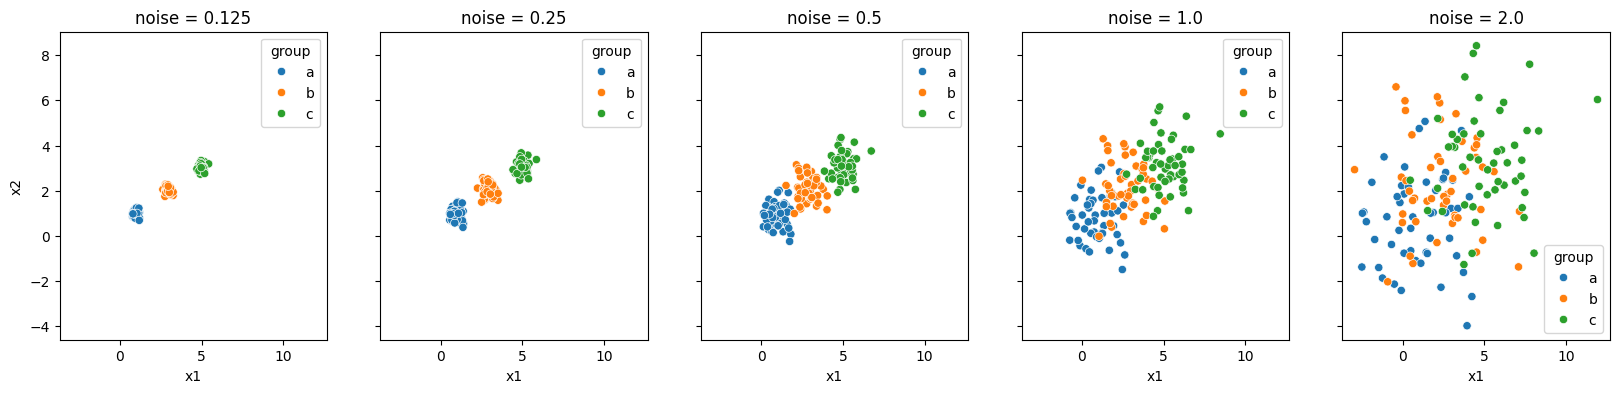

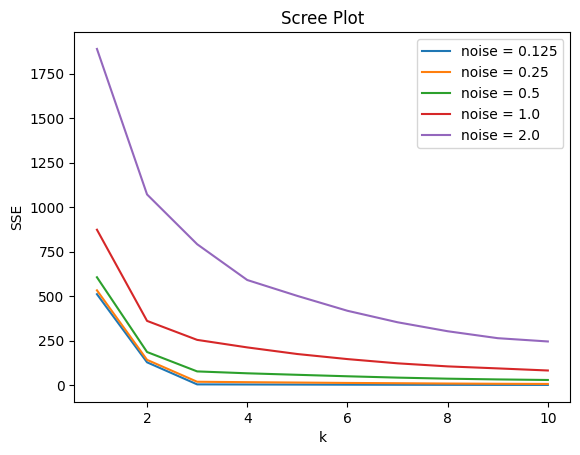

In [2]:
# Question 1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# Question 1.2

import seaborn as sns
import matplotlib.pyplot as plt

data = {"0.125": df0_125, "0.25": df0_25, "0.5": df0_5, "1.0": df1_0, "2.0": df2_0}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, (noise, d) in zip(axes, data.items()):
    sns.scatterplot(data=d, x="x1", y="x2", hue="group", ax=ax).set(title=f"noise = {noise}")
plt.show()

# Question 1.3

from sklearn.cluster import KMeans

ks = np.arange(1, 11)
for noise, d in data.items():
    X = d[["x1", "x2"]]
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE, label=f"noise = {noise}")
plt.title("Scree Plot")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

Question 1.4:

k is essentially the place we want to stop adding clusters becasue adding more decreases SSE by much less. In this simulation there are 3 groups, so k = 3 is perfect becasue SSE falls quickly until 3 and then stops. As the noise rises, the groups start to overlap and each cluster keeps cutting SSE by a similar amount.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

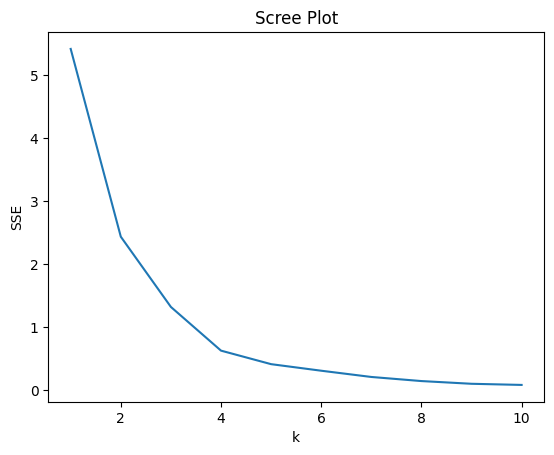

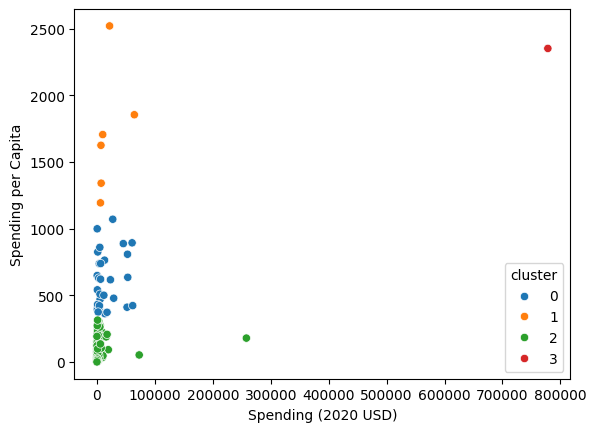

cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.88

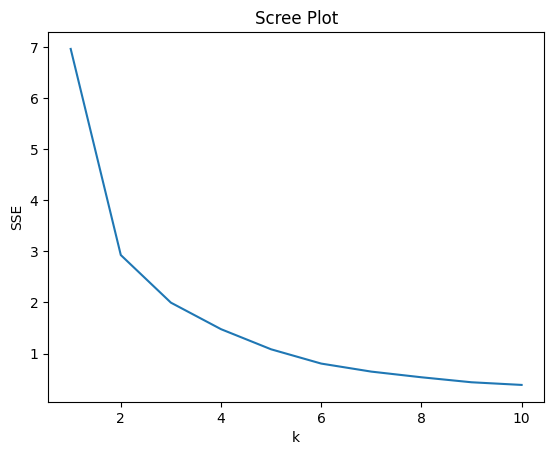

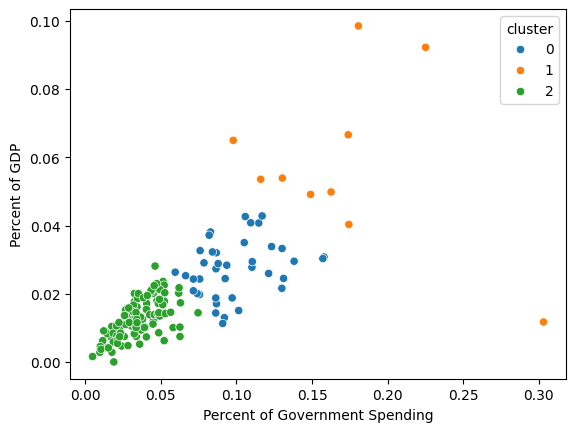

cluster                                       0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                    

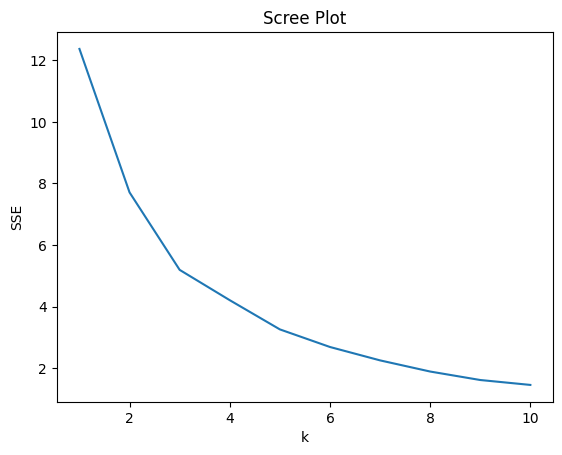

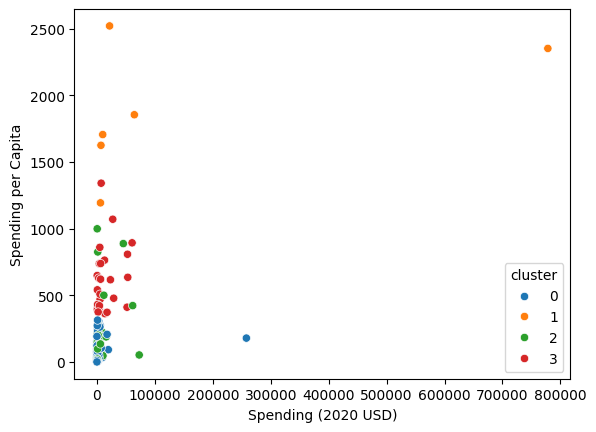

cluster                                           0              1  \
Spending (2020 USD)            count      86.000000       6.000000   
                               mean     4513.543790  147964.582042   
                               std     27841.230783  309635.189564   
                               min         8.622460    6095.708713   
                               25%        81.022976    7700.424616   
                               50%       288.061512   15897.570598   
                               75%      1138.618231   53872.942442   
                               max    257973.429834  778397.200000   
Spending per Capita            count      86.000000       6.000000   
                               mean       70.290644    1875.150751   
                               std        81.690590     489.800206   
                               min         0.580129    1193.598730   
                               25%        11.522275    1645.301864   
                    

In [4]:
# Question 2

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Question 1.1
df = pd.read_csv("SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna().copy()   # 148 rows

# Helper function to reduce repition in parts 2,3,4
def run(cols, k):
    X = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())

    # scree plot
    ks = np.arange(1, 11)
    SSE = [KMeans(n_clusters=i, n_init=10, random_state=0).fit(X).inertia_ for i in ks]
    sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
    plt.show()

    # cluster, scatter, describe
    df["cluster"] = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).labels_
    sns.scatterplot(data=df, x=cols[0], y=cols[1], hue="cluster", palette="tab10")
    plt.show()
    print(df.groupby("cluster")[cols].describe().T)
    print(df.loc[df["Country"] == "United States of America", "cluster"])

# Question 1.2
run(["Spending (2020 USD)", "Spending per Capita"], 4)

# Question 1.3
run(["Percent of Government Spending", "Percent of GDP"], 3)

# Question 1.4
run(["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"], 4)

---

Question 2 Response

1.1: No other cleaning is needed though there is some skew in the dataset.

1.2: The US is alone with 778 million total and $2,352 per capita, while cluster 1 has the highest per capita spending, cluster 0  holds large economies, and cluster 2 holds everyone else.

1.3: The US is in cluster 0 witg mean 9.9% of government spending and 2.7% of GDP, while cluster 1 is the high burden group  and cluster 2 is the low burden group.

1.4: The US is in cluster 1 with five other countries, and the rest split into lower spenders, high burden countries, and wealthy low burden countries.

1.5: Yes, it does isolate the US by size and separates high burden countries from low burden ones, and which countries group together changes depending on which variables you cluster on.

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Carter Shaffer

**Date:** 10/14/26

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 9715b8739e7a90ec6ea13e774320c22f255e7d74
- **AI tool and model used:** Claude Opus 5.5

### *Prompts used

1. Please help me revise or correct my assignment, outline things that could be improved, optimized, or removed.
2.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Add the missing written answers for Q1.2 and Q1.3, and Q2.2 to Q2.5.
2. Fix the factual and clarity errors in Q1
3. Improve the analysis of the Q1 and Q2 plots

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Should fill any gaps in the written analysis for both questions |
| 2 | Accept | Need to revise any errors in my logic for written responses |
| 2 | Accept | More in depth analysis of all plots. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

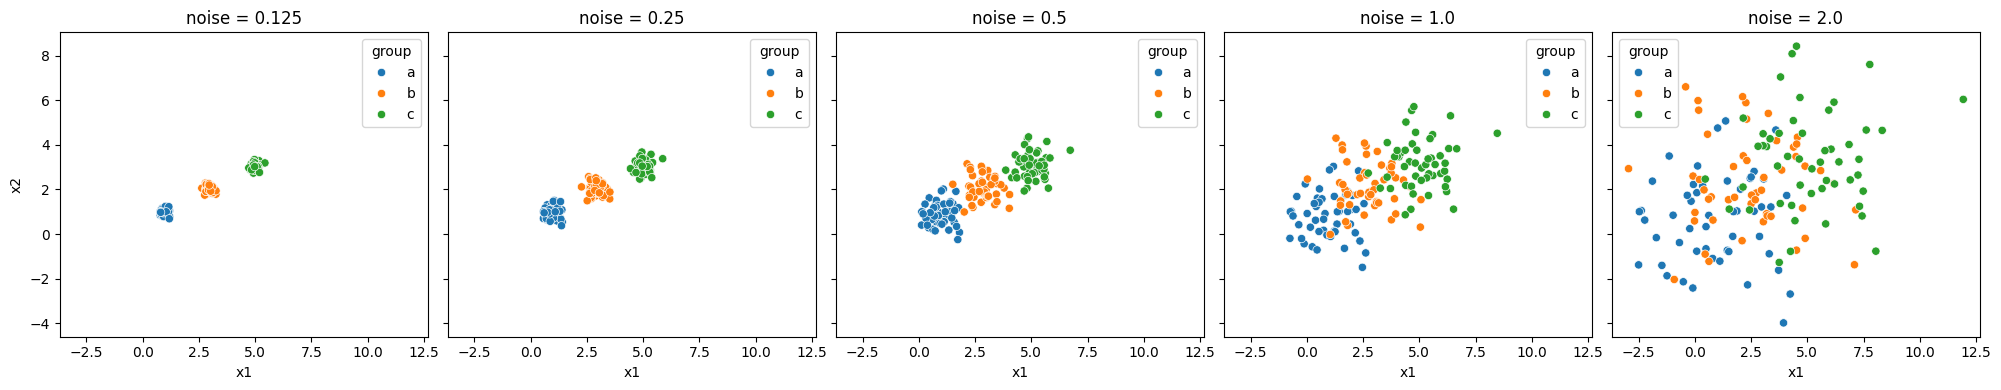

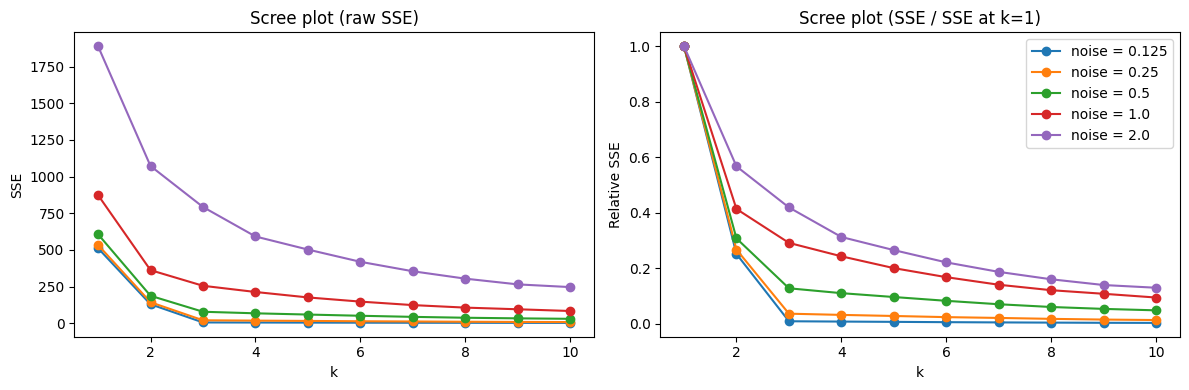

In [5]:
# Your Phase 2 solution to the problem goes here.

# Question 1
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)  # Set the seed for replicability
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0)

data = {noise: createData(noise) for noise in [0.125, 0.25, 0.5, 1.0, 2.0]}

# Question 1.2: scatterplots by true group
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, (noise, d) in zip(axes, data.items()):
    sns.scatterplot(data=d, x="x1", y="x2", hue="group", ax=ax).set(title=f"noise = {noise}")
plt.tight_layout()
plt.show()

# Question 1.3: scree plots, raw (left) and rescaled by the k=1 SSE (right)
ks = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for noise, d in data.items():
    X = d[["x1", "x2"]]
    sse = np.array([KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks])
    axes[0].plot(ks, sse, marker="o", label=f"noise = {noise}")
    axes[1].plot(ks, sse / sse[0], marker="o", label=f"noise = {noise}")
axes[0].set(title="Scree plot (raw SSE)", xlabel="k", ylabel="SSE")
axes[1].set(title="Scree plot (SSE / SSE at k=1)", xlabel="k", ylabel="Relative SSE")
axes[1].legend()
plt.tight_layout()
plt.show()

Q1.2

At noise 0.125 and 0.25 the three groups are clearly separated blobs.
At 0.5 the groups are still recognizable but their edges touch.
At 1.0 they overlap heavily.
At 2.0 the three groups are visually one cloud.
Noise sets the spread around fixed centers, so the same centers get harder to see as the spread grows.

Q1.3

On the raw plot the high-noise curves dominate the axis, so the low-noise elbows look flat. The rescaled plot fixes that.
At 0.125 and 0.25 there is a sharp elbow at k = 3, after which SSE barely falls.
At 0.5 the elbow is still visible but softer.
At 1.0 and 2.0 the curve declines smoothly with no clear bend, so I cannot confidently pick k from the plot alone.


Q1.4

SSE always falls as k increases, because more centers sit closer to the points. The elbow is where the drop changes from separating real groups to just fitting noise.
In this simulation the true k is 3. Going from 2 to 3 clusters splits a real group, so SSE falls a lot. Going past 3 only carves up noise within a group, so the gains are small.
With high noise the groups overlap, so each extra cluster cuts SSE by a similar amount and there is no clear elbow.

(148, 7)
<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.8771

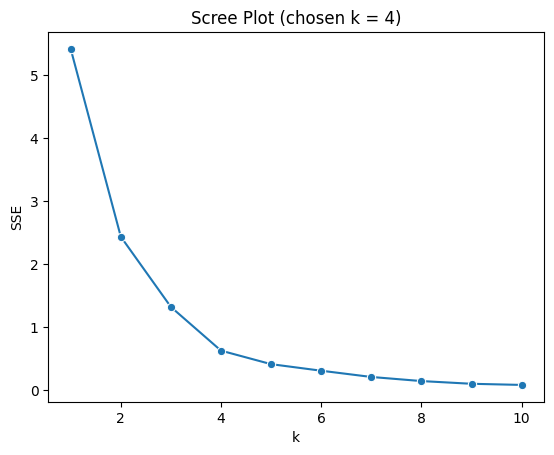

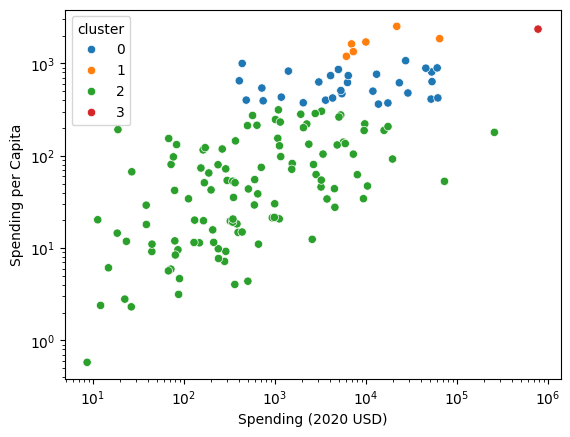

        Spending (2020 USD)                         Spending per Capita  \
                      count        mean      median               count   
cluster                                                                   
0                        30   17077.591    5857.061                  30   
1                         6   19443.362    8624.226                   6   
2                       111    4859.185     382.465                 111   
3                         1  778397.200  778397.200                   1   

                             
             mean    median  
cluster                      
0         607.479   579.005  
1        1706.722  1665.447  
2          80.061    47.057  
3        2351.632  2351.632  
Cluster 0 (30): Australia, Austria, Bahrain, Belgium, Brunei, Canada, Cyprus, Denmark, Estonia, Finland, France, Germany, Greece, Italy, Japan, Korea, South, Latvia, Lithuania, Luxembourg, Netherlands, New Zealand, Poland, Portugal, Russia, Slovakia, Spain, Sweden

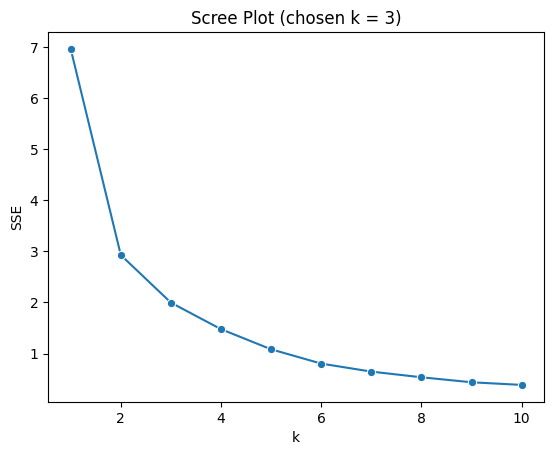

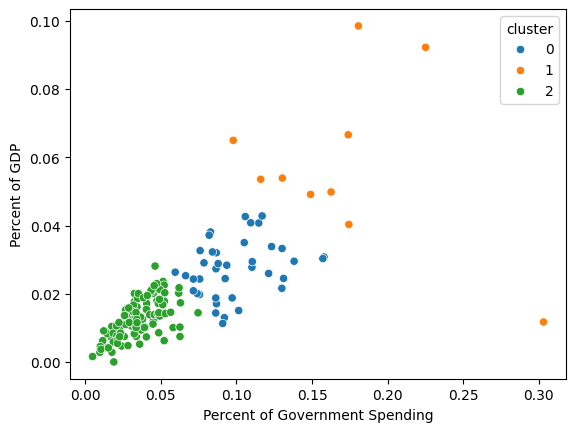

        Percent of Government Spending               Percent of GDP         \
                                 count   mean median          count   mean   
cluster                                                                      
0                                   39  0.099  0.092             39  0.027   
1                                   10  0.171  0.168             10  0.058   
2                                   99  0.036  0.034             99  0.013   

                
        median  
cluster         
0        0.028  
1        0.054  
2        0.013  
Cluster 0 (39): Bahrain, Bangladesh, Botswana, Brunei, Burkina Faso, Burundi, Cambodia, Central African Republic, Chad, Chile, Colombia, Congo, Republic, Ecuador, Equatorial Guinea, Gabon, Guinea, India, Iran, Iraq, Korea, South, Lebanon, Mali, Mauritania, Morocco, Myanmar, Namibia, Niger, Russia, Singapore, South Sudan, Sri Lanka, Sudan, Taiwan, Togo, Tunisia, Turkey, Uganda, Ukraine, United States of America
Cluster 1 (10):

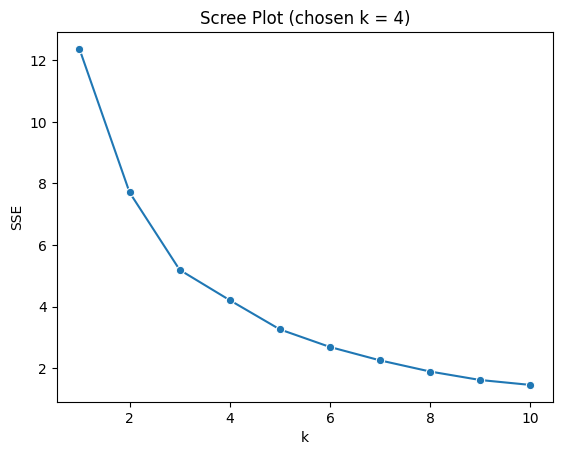

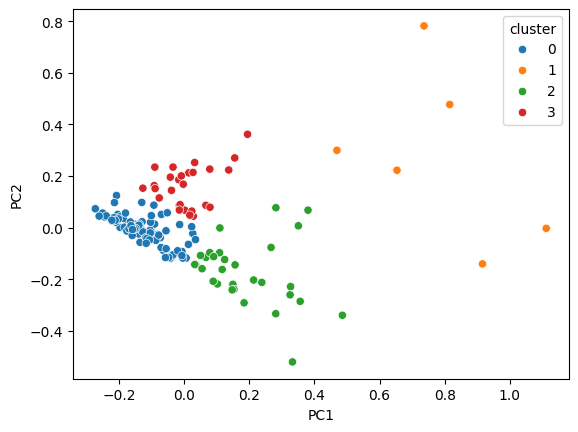

        Spending (2020 USD)                        Spending per Capita  \
                      count        mean     median               count   
cluster                                                                  
0                        86    4513.544    288.062                  86   
1                         6  147964.582  15897.571                   6   
2                        30    9073.544   1663.090                  30   
3                        26   15330.619   5857.061                  26   

                            Percent of Government Spending                \
             mean    median                          count   mean median   
cluster                                                                    
0          70.291    34.846                             86  0.043  0.040   
1        1875.151  1780.060                              6  0.135  0.113   
2         215.921   137.956                             30  0.124  0.116   
3         612.678   579.0

In [6]:
# Question 2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Question 2.1: load, filter, clean, inspect
df = pd.read_csv("SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna().copy()
print(df.shape)  # expect 148 rows
df.info()
num_cols = ["Spending (2020 USD)", "Spending per Capita",
            "Percent of Government Spending", "Percent of GDP"]
print(df[num_cols].describe())
print(df[num_cols].skew())  # spending variables are heavily right-skewed

def run(df, cols, k, log_axes=False):
    """Min-max scale cols, plot scree, cluster with k, plot, and return a labeled copy."""
    X = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())

    # scree plot
    ks = np.arange(1, 11)
    sse = [KMeans(n_clusters=i, n_init=10, random_state=0).fit(X).inertia_ for i in ks]
    sns.lineplot(x=ks, y=sse, marker="o").set(title=f"Scree Plot (chosen k = {k})",
                                              xlabel="k", ylabel="SSE")
    plt.show()

    # cluster
    out = df.copy()
    out["cluster"] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)

    # scatter (first two vars directly, or a PCA projection for more than two)
    if len(cols) == 2:
        ax = sns.scatterplot(data=out, x=cols[0], y=cols[1], hue="cluster", palette="tab10")
        if log_axes:
            ax.set(xscale="log", yscale="log")
    else:
        p = PCA(n_components=2).fit_transform(X)
        out["PC1"], out["PC2"] = p[:, 0], p[:, 1]
        sns.scatterplot(data=out, x="PC1", y="PC2", hue="cluster", palette="tab10")
    plt.show()

    # compact summary, then the member countries
    print(out.groupby("cluster")[cols].agg(["count", "mean", "median"]).round(3))
    for c, g in out.groupby("cluster"):
        print(f"Cluster {c} ({len(g)}):", ", ".join(sorted(g["Country"])))
    print("United States cluster:",
          out.loc[out["Country"] == "United States of America", "cluster"].iloc[0])
    return out

# Question 2.2
df2 = run(df, ["Spending (2020 USD)", "Spending per Capita"], k=4, log_axes=True)

# Question 2.3
df3 = run(df, ["Percent of Government Spending", "Percent of GDP"], k=3)

# Question 2.4
df4 = run(df, num_cols, k=4)

Q2.1

After dropping missing values there are 148 countries, and the four variables are numeric.
The main issue is skew. A few very large spenders dominate the two spending variables, so I min-max normalize before clustering. The US is an extreme outlier that compresses most countries near 0.
A log transform before scaling would be a reasonable extra step. I can report it as a robustness check.

Q2.2

I chose k = 4 from the elbow in the scree plot.
The clusters were:
Cluster 3: the United States alone. Its spending is about 778,397 and its spending per capita is about $2,352. Spending is presumably in millions of USD (the SIPRI convention), so about $778 billion. Check the file’s notes.
Cluster 1: 6 countries with the highest per capita spending, at about $1,700 on average.
Cluster 0: 30 mid-to-large spenders.
Cluster 2: the other 111 countries, with low spending per capita (mean about $80).


Q2.3

I chose k = 3. The clusters split by how heavy the burden is:
Cluster 1: 10 high-burden countries, with a mean of about 17% of government spending and 5.8% of GDP.
Cluster 0: 39 moderate-burden countries, with a mean of about 9.9% of government spending and 2.7% of GDP. The US is here.
Cluster 2: 99 low-burden countries, with a mean of about 3.6% of government spending and 1.3% of GDP.
Unlike part 2, the US is not an outlier here. It looks like a typical moderate spender relative to its economy.

Q2.4

With all four variables (k = 4), the clusters have 86, 6, 30 and 26 countries.
The US is in cluster 1 with five other countries, which have high total spending and the highest spending per capita.
The remaining clusters split by burden:
Cluster 2 (30 countries): a high-burden group, at about 12% of government spending.
Cluster 3 (26 countries): a low-burden but fairly high per capita group, at about $613 per head.
Cluster 0 (86 countries): low spenders overall.
This blends parts 2 and 3. Size and per capita spending separate the top group, and the percent measures separate the others.

Q2.5

Patterns it found:
The US stands out on absolute size, as in part 2.
A small group is separated by very high spending per capita.
Countries with a high share of government spending or GDP form their own clusters.
The grouping changes with the variables used. Size, per capita spending and burden each tell a different story.

### *Reflection on AI assistance
In your own words without generative AI.

On this assignment the main improvement from AI was essentially just fixing a few numerical errors in my analysis, and being more clear in my question responses. This deffinately helps the thuroughness of my submission, as I had left out some important resonses to questions that AI caught and helped me to correct. Other than these few revisions, there were not any more improvements that AI helped me make. However, I really appreciated the ability to use AI as a tool to double check my strategy, and summarize other ways of potentially completing this assignment. All in all, I think that AI was a great resource that helped the quality of my final submission.